In [1]:
# https://github.com/jeandeducla/ML-Time-Series/blob/master/SVM-Accelerometer.ipynb
import pandas as pd
import numpy as np
import datetime as dt

In [2]:
import matplotlib.pyplot as plt

In [3]:
import scipy.stats as st
from scipy.fftpack import fft, fftfreq 
from scipy.signal import argrelextrema
import operator

In [277]:
df=pd.read_csv('final_db.csv')

In [278]:
df.head()

,Unnamed: 0,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
0,0,2019-11-06 11:37:13.038174,19.48,54.86,128.0,563.0,476.0,731.0,649.0,565.0,128.0
1,1,2019-11-06 11:37:32.744996,19.59,54.23,129.0,563.0,477.0,731.0,649.0,565.0,125.0
2,2,2019-11-06 11:37:53.018087,19.63,54.05,128.0,566.0,478.0,732.0,649.0,565.0,125.0
3,3,2019-11-06 11:38:13.093151,19.64,53.74,128.0,566.0,478.0,732.0,649.0,565.0,125.0
4,4,2019-11-06 11:38:33.032832,19.67,53.53,128.0,569.0,480.0,732.0,650.0,565.0,125.0


In [279]:
df.describe()

,Unnamed: 0,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
count,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000,491484.000000
mean,181977.050653,20.101878,52.919115,97.511565,534.631428,506.183123,719.528914,673.243607,611.864179,119.222447
std,126711.336496,2.183414,4.409504,38.806471,34.001189,48.595386,29.902103,34.637434,41.189089,34.279827
min,0.000000,13.530000,38.160000,21.000000,408.000000,262.000000,514.000000,447.000000,355.000000,74.000000
25%,61525.000000,18.830000,49.580000,71.000000,508.000000,475.000000,704.000000,657.000000,591.000000,102.000000
50%,170410.500000,20.150000,53.340000,101.000000,522.000000,515.000000,720.000000,675.000000,614.000000,113.000000
75%,293281.250000,21.290000,56.550000,115.000000,557.000000,539.000000,738.000000,692.000000,637.000000,127.000000
max,416152.000000,26.140000,69.260000,591.000000,632.000000,626.000000,808.000000,777.000000,727.000000,918.000000


/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_60533/145818903.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = df.corr()


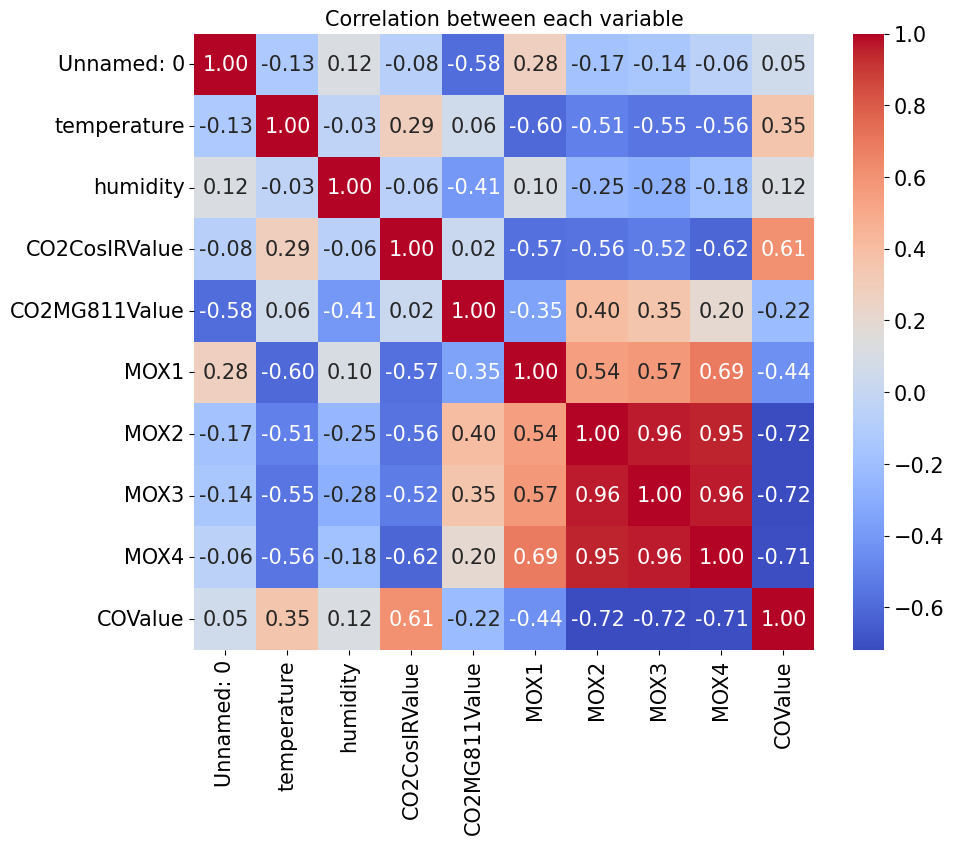

In [280]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(10, 8))
heatmap=sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 15})
plt.title('Correlation between each variable', fontsize=15)
heatmap.tick_params(axis='x', labelsize=15)
heatmap.tick_params(axis='y', labelsize=15)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=15)
plt.show()

In [281]:
del df['Unnamed: 0']

In [282]:
# need to convert time string to time format for easy processing
df['recordtime'] = df['timestamp']
df.recordtime =df.recordtime.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.recordtime =df.recordtime.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [283]:
# sort values from small time to large time
# how much signal is difference from the prevous time to current time is important
df.sort_values(by='recordtime', inplace=True, ascending=True)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'].dt.floor(freq='30T')

In [284]:
# always check the latest data
df.head()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue,recordtime
0,2019-11-06 11:30:00,19.48,54.86,128.0,563.0,476.0,731.0,649.0,565.0,128.0,2019-11-06 11:37:13
1,2019-11-06 11:30:00,19.59,54.23,129.0,563.0,477.0,731.0,649.0,565.0,125.0,2019-11-06 11:37:32
2,2019-11-06 11:30:00,19.63,54.05,128.0,566.0,478.0,732.0,649.0,565.0,125.0,2019-11-06 11:37:53
3,2019-11-06 11:30:00,19.64,53.74,128.0,566.0,478.0,732.0,649.0,565.0,125.0,2019-11-06 11:38:13
4,2019-11-06 11:30:00,19.67,53.53,128.0,569.0,480.0,732.0,650.0,565.0,125.0,2019-11-06 11:38:33


In [285]:
df.tail()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue,recordtime
491479,2021-02-13 11:30:00,20.62,57.75,62.0,518.0,524.0,698.0,642.0,591.0,157.0,2021-02-13 11:56:53
491480,2021-02-13 11:30:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:57:14
491481,2021-02-13 11:30:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:57:33
491482,2021-02-13 11:30:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:57:54
491483,2021-02-13 11:30:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:58:14


In [286]:
df.shape

(491484, 11)

In [287]:
# look the count for each time group
group_count = pd.DataFrame(df.groupby('timestamp').count()['humidity'])
group_count.reset_index(inplace=True)
group_count.rename(columns={"humidity": "countv"}, inplace=True)


In [288]:
# some of the time group has low number of data missing
# Fillup them
group_count.countv.unique()

array([69, 90, 89, 91, 87, 80,  5,  2, 50, 31, 82, 72, 88, 81, 85, 35, 67,
       74, 36, 84, 62, 58, 47,  4, 55, 61, 37])

In [289]:
# these time group has low count - 
# lot of data is missing for these. So they need to be removed
time_low_count = group_count[group_count.countv<75]
time_low_count

,timestamp,countv
0,2019-11-06 11:30:00,69
1553,2019-12-08 20:00:00,5
1554,2019-12-09 10:30:00,2
1555,2019-12-09 11:00:00,50
1556,2019-12-09 11:30:00,31
2041,2019-12-19 14:00:00,72
3834,2020-01-25 22:30:00,35
3835,2020-01-25 23:00:00,67
3842,2020-01-26 02:30:00,74
3850,2020-01-26 06:30:00,72


In [290]:
# np.unique([(list(df.recordtime)[i] - list(df.recordtime)[i-1]).seconds for i in range(1, len(df.recordtime))])

In [291]:
df.columns

Index(['timestamp', 'temperature', 'humidity', 'CO2CosIRValue',
       'CO2MG811Value', 'MOX1', 'MOX2', 'MOX3', 'MOX4', 'COValue',
       'recordtime'],
      dtype='object')

In [292]:
# investigate how these data is missing
processed_df = df[['temperature', 'humidity', 'CO2CosIRValue','CO2MG811Value', 'MOX1', 'MOX4', 'COValue']].copy()
processed_df = processed_df.rolling(5).mean()
processed_df['timestamp'] = df['timestamp']
processed_df['recordtime'] = df['recordtime']

In [293]:
# ndf = pd.DataFrame(columns=df.columns)
# for time in df.recordtime:
#     current_value = list(df[df.recordtime==time].values[0])
#     ndf.loc[len(ndf)] = current_value

#     next_time = time + dt.timedelta(seconds=22)
#     temp = df[(df.recordtime>time) & (df.recordtime<=next_time)]

#     if len(temp) < 1:
#         current_value[-1] = next_time
#         ndf.loc[len(ndf)] = current_value

#         next_time = next_time + dt.timedelta(seconds=22)
#         temp = df[(df.recordtime>time) & (df.recordtime<=next_time)]

#         if len(temp) < 1:
#             current_value[-1] = next_time
#             ndf.loc[len(ndf)] = current_value

In [294]:
processed_df=processed_df[~processed_df.timestamp.isin(time_low_count.timestamp)]

In [295]:
processed_df['timestamp'].unique()

array(['2019-11-06T12:00:00.000000000', '2019-11-06T12:30:00.000000000',
       '2019-11-06T13:00:00.000000000', ...,
       '2021-02-13T10:30:00.000000000', '2021-02-13T11:00:00.000000000',
       '2021-02-13T11:30:00.000000000'], dtype='datetime64[ns]')

In [296]:
processed_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 489939 entries, 69 to 491483
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   temperature    489939 non-null  float64       
 1   humidity       489939 non-null  float64       
 2   CO2CosIRValue  489939 non-null  float64       
 3   CO2MG811Value  489939 non-null  float64       
 4   MOX1           489939 non-null  float64       
 5   MOX4           489939 non-null  float64       
 6   COValue        489939 non-null  float64       
 7   timestamp      489939 non-null  datetime64[ns]
 8   recordtime     489939 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(7)
memory usage: 37.4 MB


In [297]:
df['timestamp']

0        2019-11-06 11:30:00
1        2019-11-06 11:30:00
2        2019-11-06 11:30:00
3        2019-11-06 11:30:00
4        2019-11-06 11:30:00
                 ...        
491479   2021-02-13 11:30:00
491480   2021-02-13 11:30:00
491481   2021-02-13 11:30:00
491482   2021-02-13 11:30:00
491483   2021-02-13 11:30:00
Name: timestamp, Length: 491484, dtype: datetime64[ns]

In [298]:
processed_df

,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX4,COValue,timestamp,recordtime
69,19.812,48.102,87.0,609.8,549.4,645.4,103.8,2019-11-06 12:00:00,2019-11-06 12:00:12
70,19.812,48.048,86.4,610.6,550.8,647.4,103.4,2019-11-06 12:00:00,2019-11-06 12:00:33
71,19.820,47.986,85.8,611.2,552.0,649.2,103.0,2019-11-06 12:00:00,2019-11-06 12:00:53
72,19.840,47.882,85.2,611.8,553.0,650.2,102.6,2019-11-06 12:00:00,2019-11-06 12:01:13
73,19.856,47.784,84.4,612.4,553.8,651.0,102.2,2019-11-06 12:00:00,2019-11-06 12:01:33
...,...,...,...,...,...,...,...,...,...
491479,20.648,57.720,62.0,517.6,524.6,591.0,156.4,2021-02-13 11:30:00,2021-02-13 11:56:53
491480,20.634,57.738,62.0,517.8,524.4,591.0,156.6,2021-02-13 11:30:00,2021-02-13 11:57:14
491481,20.620,57.750,62.0,518.0,524.2,591.0,156.8,2021-02-13 11:30:00,2021-02-13 11:57:33
491482,20.620,57.748,62.2,518.0,524.0,591.0,157.0,2021-02-13 11:30:00,2021-02-13 11:57:54


In [299]:
processed_df[processed_df['timestamp']=='2019-11-06 13:00:00+01:00']['MOX1']

Series([], Name: MOX1, dtype: float64)

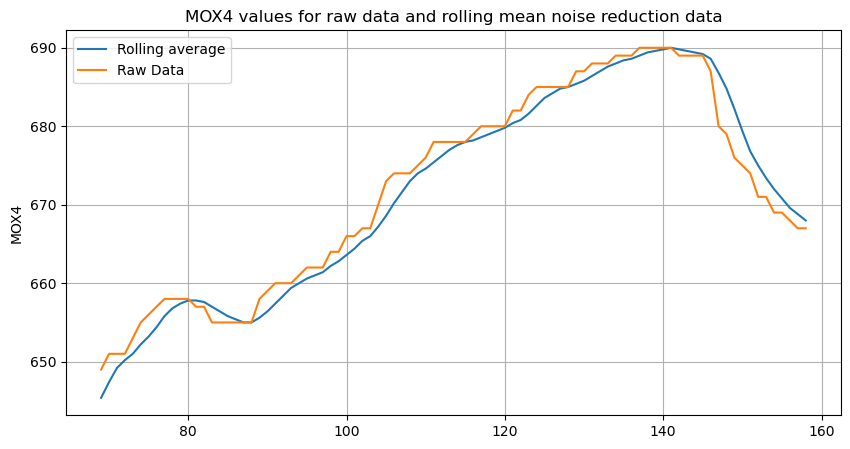

In [300]:
import matplotlib.pyplot as plt

# Assuming processed_df and df are your DataFrames

# Plotting the processed data
processed_df[processed_df['timestamp'] == '2019-11-06 12:00:00']['MOX4'].plot(kind='line', figsize=(10, 5), label='Rolling average')
plt.title('MOX1 values for 1-hour timeframe after using rolling mean noise reduction technique ')
plt.ylabel('MOX1')
plt.legend(loc='upper left')
plt.grid(True)

# Plotting the raw data on the same plot
df[df['timestamp'] == '2019-11-06 12:00:00']['MOX4'].plot(kind='line', figsize=(10, 5), label='Raw Data')
plt.title('MOX4 values for raw data and rolling mean noise reduction data')
plt.ylabel('MOX4')
plt.legend(loc='upper left')
plt.grid(True)

# Display the combined plot
plt.show()

In [301]:
group_count = group_count[~group_count.timestamp.isin(time_low_count.timestamp)]

In [302]:
group_count.shape

(5445, 2)

In [303]:
#del features_df['timestamp']
del features_df['countv']

In [304]:
features_df.tail(20)

,timestamp,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
0,NaT,19.535722,20.596,19.000,0.305909,0.774307,0.935235,0.468,0.22600,3516.291861,...,7.809797,6.874733,6.647422,6.001116,4.033897,0.038889,0.083333,0.061111,0.027778,0.127778
777,NaT,22.702756,23.212,22.182,0.275429,0.114866,-0.981927,0.424,0.24200,4086.756378,...,339.678072,338.167251,334.038206,330.462912,326.666480,0.094444,0.083333,0.072222,0.111111,0.122222
778,NaT,23.311256,23.740,22.846,0.249802,-0.328294,-0.991952,0.398,0.21000,4196.256628,...,154.159208,144.772140,129.999355,108.266537,100.081974,0.027778,0.050000,0.072222,0.094444,0.105556
779,NaT,23.568978,23.980,23.114,0.182642,-0.318762,0.328123,0.220,0.09600,4242.419489,...,22.678520,18.165815,17.573069,17.228401,16.406817,0.033333,0.105556,0.116667,0.094444,0.011111
1918,NaT,15.485860,15.692,15.200,0.138259,-0.409386,-0.945409,0.208,0.11414,2787.471667,...,5.655032,4.967864,4.888241,3.691338,3.541486,0.055556,0.033333,0.066667,0.044444,0.077778
1927,NaT,17.640722,17.842,17.488,0.105676,0.137421,-0.981002,0.196,0.07800,3175.390361,...,7.639025,7.456051,5.760687,5.477700,4.408306,0.050000,0.033333,0.100000,0.061111,0.022222
1931,NaT,19.143944,19.240,18.940,0.065729,-1.335920,1.399916,0.060,0.02800,3445.908972,...,6.588363,5.823813,4.284885,3.994927,3.333330,0.044444,0.055556,0.066667,0.105556,0.033333
1932,NaT,19.231678,19.418,18.932,0.131284,-0.565658,-0.564542,0.196,0.09000,3461.849839,...,7.575360,5.884417,5.325401,4.598350,3.591865,0.044444,0.016667,0.077778,0.111111,0.288889
2102,NaT,22.900611,23.470,22.226,0.411950,-0.131453,-1.483589,0.784,0.38800,4121.981306,...,11.958226,11.489894,10.736711,10.425858,9.740712,0.005556,0.027778,0.038889,0.133333,0.061111
2103,NaT,22.092733,22.220,21.982,0.053481,0.153548,-0.651887,0.078,0.04000,3976.628367,...,7.136132,4.852401,4.416709,4.168411,4.130437,0.050000,0.083333,0.116667,0.144444,0.133333


In [305]:
def stat_area_features(x, Te=1.0):

    mean_ts = np.mean(x, axis=1).reshape(-1,1) # mean
    max_ts = np.amax(x, axis=1).reshape(-1,1) # max
    min_ts = np.amin(x, axis=1).reshape(-1,1) # min
    std_ts = np.std(x, axis=1).reshape(-1,1) # std
    skew_ts = st.skew(x, axis=1).reshape(-1,1) # skew
    kurtosis_ts = st.kurtosis(x, axis=1).reshape(-1,1) # kurtosis 
    iqr_ts = st.iqr(x, axis=1).reshape(-1,1) # interquartile rante
    mad_ts = np.median(np.sort(abs(x - np.median(x, axis=1).reshape(-1,1)),
                               axis=1), axis=1).reshape(-1,1) # median absolute deviation
    area_ts = np.trapz(x, axis=1, dx=Te).reshape(-1,1) # area under curve
    sq_area_ts = np.trapz(x ** 2, axis=1, dx=Te).reshape(-1,1) # area under curve ** 2

    return np.concatenate((mean_ts,max_ts,min_ts,std_ts,skew_ts,kurtosis_ts,
                           iqr_ts,mad_ts,area_ts,sq_area_ts), axis=1)

In [306]:
def frequency_domain_features(x, Te=1.0):

    # As the DFT coefficients and their corresponding frequencies are symetrical arrays
    # with respect to the middle of the array we need to know if the number of readings 
    # in x is even or odd to then split the arrays...
    if x.shape[1]%2 == 0:
        N = int(x.shape[1]/2)
    else:
        N = int(x.shape[1]/2) - 1
    xf = np.repeat(fftfreq(x.shape[1],d=Te)[:N].reshape(1,-1), x.shape[0], axis=0) # frequencies
    dft = np.abs(fft(x, axis=1))[:,:N] # DFT coefficients   
    
    # statistical and area features
    dft_features = stat_area_features(dft, Te=1.0)
    # weighted mean frequency
    dft_weighted_mean_f = np.average(xf, axis=1, weights=dft).reshape(-1,1)
    # 5 first DFT coefficients 
    dft_first_coef = dft[:,:5]    
    # 5 first local maxima of DFT coefficients and their corresponding frequencies
    dft_max_coef = np.zeros((x.shape[0],5))
    dft_max_coef_f = np.zeros((x.shape[0],5))
    for row in range(x.shape[0]):
        # finds all local maximas indexes
        extrema_ind = argrelextrema(dft[row,:], np.greater, axis=0) 
        # makes a list of tuples (DFT_i, f_i) of all the local maxima
        # and keeps the 5 biggest...
        extrema_row = sorted([(dft[row,:][j],xf[row,j]) for j in extrema_ind[0]],
                             key=operator.itemgetter(0), reverse=True)[:5] 
        for i, ext in enumerate(extrema_row):
            dft_max_coef[row,i] = ext[0]
            dft_max_coef_f[row,i] = ext[1]    
    
    return np.concatenate((dft_features,dft_weighted_mean_f,dft_first_coef,
                           dft_max_coef,dft_max_coef_f), axis=1)


In [307]:
def convert_to_list(data, column_name):
    Unique_time = data.timestamp.unique()
    X = []
    for time in Unique_time:
        values = data[data.timestamp==time][column_name].tolist()
        if len(values)<91:
            resample_len=91-len(values)
            new_data = [np.mean(values)] * resample_len
            values.extend(new_data)
        X.append(values)
    return np.array(X)

In [308]:
def make_feature(data, column_name, Te=1.0):
    # convert data into list of lists
    x=convert_to_list(data, column_name)

    # extract statistical feature
    x_stat=stat_area_features(x)
    x_stat=pd.DataFrame(x_stat)
    x_stat.columns=[column_name+'_stat_'+ str(i) for i in range(x_stat.shape[1])]

    # extract statistical feature for the signal difference
    xt_jerk = stat_area_features((x[:, 1:]-x[:, :-1])/Te, Te=Te)
    xt_jerk = pd.DataFrame(xt_jerk)
    xt_jerk.columns=[column_name + '_xt_jerk_' + str(i) for i in range(xt_jerk.shape[1])]
    x_final=pd.concat([x_stat, xt_jerk], axis=1)

    
    # extract frequency_domain_features
    x_domain=frequency_domain_features(x)
    x_domain=pd.DataFrame(x_domain)
    x_domain.columns=[column_name +'_tm_dom_'+ str(i) for i in range(x_domain.shape[1])]
    x_final = pd.concat([x_final, x_domain], axis=1)

    # extract frequency_domain_features for the signal difference
    xf_jerk = frequency_domain_features((x[:, 1:]-x[:, :-1])/Te, Te=1/Te)
    xf_jerk = pd.DataFrame(xf_jerk)
    xf_jerk.columns=[column_name + '_xf_jerk_' + str(i) for i in range(xf_jerk.shape[1])]
    x_final = pd.concat([x_final, xf_jerk], axis=1)

    return x_final

In [309]:
# test only for humidity column
humidity=make_feature(processed_df, column_name='humidity')

In [310]:
humidity.head()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
0,48.196533,50.010,46.354,0.816035,0.215408,-0.082536,0.968,0.512000,4337.735267,209126.674031,...,4.322748,4.041555,2.194898,2.042472,1.676828,0.022222,0.055556,0.122222,0.100000,0.266667
1,49.980622,51.770,48.422,0.857975,0.351763,0.155644,0.445,0.219378,4498.821311,224948.490881,...,5.511092,2.240691,1.653291,1.633251,1.560932,0.033333,0.111111,0.155556,0.344444,0.300000
2,51.026622,52.768,49.840,0.704684,0.255045,-0.339869,0.973,0.494000,4592.306311,234370.475390,...,4.102605,3.401411,2.406536,2.050560,1.987555,0.022222,0.066667,0.155556,0.288889,0.344444
3,51.481200,52.940,49.168,1.079798,-0.680607,-0.424419,1.194,0.762000,4632.674600,238568.339753,...,6.650002,3.559130,2.293070,2.043538,1.966401,0.033333,0.077778,0.277778,0.144444,0.344444
4,50.670000,52.820,49.784,0.741617,1.601571,2.109092,0.492,0.236000,4560.676000,231158.271712,...,5.016612,4.790626,1.470415,1.414422,0.437151,0.044444,0.022222,0.088889,0.133333,0.177778


In [311]:
humidity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5445 entries, 0 to 5444
Data columns (total 72 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   humidity_stat_0      5445 non-null   float64
 1   humidity_stat_1      5445 non-null   float64
 2   humidity_stat_2      5445 non-null   float64
 3   humidity_stat_3      5445 non-null   float64
 4   humidity_stat_4      5445 non-null   float64
 5   humidity_stat_5      5445 non-null   float64
 6   humidity_stat_6      5445 non-null   float64
 7   humidity_stat_7      5445 non-null   float64
 8   humidity_stat_8      5445 non-null   float64
 9   humidity_stat_9      5445 non-null   float64
 10  humidity_xt_jerk_0   5445 non-null   float64
 11  humidity_xt_jerk_1   5445 non-null   float64
 12  humidity_xt_jerk_2   5445 non-null   float64
 13  humidity_xt_jerk_3   5445 non-null   float64
 14  humidity_xt_jerk_4   5445 non-null   float64
 15  humidity_xt_jerk_5   5445 non-null   f

In [312]:
humidity.describe()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
count,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,...,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000,5445.000000
mean,52.906810,53.646983,52.132393,0.432262,-0.076153,-0.442318,0.642196,0.276580,4761.615087,253669.639531,...,2.139799,1.480830,1.067000,0.848879,0.733025,0.037768,0.061069,0.105108,0.166661,0.230456
std,4.364734,4.211488,4.586198,0.427027,0.681728,1.314712,0.739796,0.296264,392.842795,41089.633942,...,1.811730,1.287253,0.959544,0.802155,0.739991,0.021134,0.041736,0.069573,0.098117,0.109073
min,40.434511,41.156000,38.174000,0.022141,-4.728605,-1.845860,0.023000,0.012000,3633.909256,147615.539916,...,0.180209,0.138035,0.051762,0.050032,0.044646,0.011111,0.011111,0.011111,0.011111,0.011111
25%,49.571800,50.490000,48.606000,0.172556,-0.473924,-1.113735,0.228000,0.106000,4461.538022,221202.180220,...,0.946276,0.642619,0.449884,0.353772,0.292828,0.022222,0.033333,0.066667,0.100000,0.133333
50%,53.317556,54.044000,52.552000,0.298308,-0.068455,-0.721828,0.422000,0.188000,4798.558378,255877.161581,...,1.520004,1.050278,0.753498,0.591523,0.505764,0.033333,0.055556,0.100000,0.133333,0.244444
75%,56.535356,57.114000,55.938000,0.539305,0.338287,-0.162409,0.756000,0.332000,5088.033678,287651.105042,...,2.759109,1.910422,1.345698,1.065323,0.897713,0.044444,0.077778,0.122222,0.244444,0.311111
max,63.877511,69.208000,62.912000,4.856167,3.852857,25.346367,9.918000,4.103489,5749.566756,367362.332645,...,16.006737,14.232679,9.724539,9.659068,9.615124,0.300000,0.477778,0.477778,0.477778,0.477778


In [313]:
# Get for all columns
features_df = group_count.copy()
for column_name in processed_df.columns:
    if column_name not in ("timestamp", 'recordtime'):
        ndf=make_feature(processed_df, column_name=column_name)
        features_df=pd.concat([features_df, ndf], axis=1)
    print(column_name)

temperature
humidity
CO2CosIRValue


/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_60533/2105657651.py:7: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  skew_ts = st.skew(x, axis=1).reshape(-1,1) # skew
/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_60533/2105657651.py:8: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  kurtosis_ts = st.kurtosis(x, axis=1).reshape(-1,1) # kurtosis


ZeroDivisionError: Weights sum to zero, can't be normalized

In [ ]:
features_df.shape

In [244]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2741 entries, 1 to 2564
Columns: 506 entries, timestamp to COValue_xf_jerk_25
dtypes: datetime64[ns](1), float64(505)
memory usage: 10.6 MB


In [245]:
features_df.head()

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
1,2019-11-06 12:00:00,180.0,19.688556,20.728,19.130,0.374229,1.031173,0.910596,0.462,0.214,...,7.351823,5.303929,4.505329,4.394617,4.329219,0.038889,0.055556,0.094444,0.072222,0.016667
2,2019-11-06 13:00:00,180.0,20.205556,20.748,19.370,0.349072,-0.619563,-0.402648,0.460,0.254,...,29.032949,11.367457,8.945521,8.561689,8.165210,0.011111,0.088889,0.050000,0.066667,0.077778
3,2019-11-06 14:00:00,180.0,20.318089,20.880,19.720,0.277944,0.300187,-0.586326,0.398,0.152,...,6.541285,5.889202,5.209887,4.722085,3.658333,0.044444,0.033333,0.127778,0.022222,0.066667
4,2019-11-06 15:00:00,180.0,19.510268,20.298,19.112,0.228919,0.376007,0.202164,0.368,0.150,...,9.303258,6.887069,5.870743,5.498729,5.073442,0.055556,0.072222,0.122222,0.472222,0.327778
5,2019-11-06 16:00:00,179.0,21.372044,22.098,19.966,0.483562,-1.217146,0.962862,0.622,0.268,...,7.034767,6.398314,5.169879,5.013221,4.993153,0.100000,0.133333,0.033333,0.316667,0.150000


In [246]:
features_df.describe()

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
count,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,...,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000,2721.000000
mean,179.915105,20.110524,20.582035,19.681615,0.245473,0.063175,-0.436575,0.371385,0.163751,3619.895013,...,12.204842,9.511596,8.361183,7.624144,6.946989,0.046043,0.061903,0.079405,0.097233,0.121522
std,1.098024,2.154787,2.252094,2.089652,0.192413,0.661209,1.203258,0.342848,0.145072,387.877038,...,23.352899,18.210018,15.449213,14.533172,11.747449,0.028618,0.043840,0.061325,0.081408,0.096313
min,157.000000,13.885833,14.388000,13.530000,0.034312,-2.565751,-1.914935,0.042000,0.021044,2499.465917,...,2.486781,2.406331,2.183063,2.009105,1.980544,0.005556,0.005556,0.005556,0.005556,0.005556
25%,180.000000,18.843222,19.324000,18.454000,0.113016,-0.350367,-1.078813,0.158000,0.072000,3391.739611,...,6.334714,5.206950,4.506357,4.015125,3.613756,0.027778,0.033333,0.038889,0.044444,0.061111
50%,180.000000,20.136889,20.428000,19.830000,0.170535,0.030270,-0.716279,0.248000,0.114000,3624.769444,...,7.703540,6.288430,5.403672,4.906390,4.410763,0.044444,0.055556,0.066667,0.083333,0.100000
75%,180.000000,21.266100,21.836000,20.882000,0.322709,0.424287,-0.178564,0.458000,0.204000,3827.961050,...,10.303124,8.255821,7.336443,6.694925,6.259171,0.055556,0.077778,0.105556,0.116667,0.133333
max,181.000000,25.582322,26.140000,25.060000,1.423358,3.753943,14.430361,3.052000,1.176000,4604.841161,...,708.412561,626.355117,486.421999,461.033716,326.666480,0.322222,0.488889,0.488889,0.488889,0.488889


In [247]:
features_stat_df = pd.DataFrame(features_df.describe())

In [466]:
column__with_variance = features_stat_df.columns[(features_stat_df.loc["std"]/features_stat_df.loc["mean"]) > 1]

In [467]:
column__with_variance = list(column__with_variance)
len(column__with_variance), column__with_variance

(201,
 ['temperature_stat_4',
  'temperature_xt_jerk_0',
  'temperature_xt_jerk_1',
  'temperature_xt_jerk_4',
  'temperature_xt_jerk_8',
  'temperature_xt_jerk_9',
  'temperature_tm_dom_2',
  'temperature_tm_dom_6',
  'temperature_tm_dom_7',
  'temperature_xf_jerk_2',
  'temperature_xf_jerk_9',
  'temperature_xf_jerk_11',
  'humidity_stat_6',
  'humidity_xt_jerk_1',
  'humidity_xt_jerk_5',
  'humidity_xt_jerk_8',
  'humidity_xt_jerk_9',
  'humidity_tm_dom_2',
  'humidity_tm_dom_6',
  'humidity_tm_dom_7',
  'humidity_tm_dom_12',
  'humidity_tm_dom_13',
  'humidity_xf_jerk_2',
  'humidity_xf_jerk_9',
  'humidity_xf_jerk_11',
  'humidity_xf_jerk_12',
  'humidity_xf_jerk_13',
  'CO2CosIRValue_stat_3',
  'CO2CosIRValue_stat_4',
  'CO2CosIRValue_stat_6',
  'CO2CosIRValue_stat_7',
  'CO2CosIRValue_stat_9',
  'CO2CosIRValue_xt_jerk_0',
  'CO2CosIRValue_xt_jerk_1',
  'CO2CosIRValue_xt_jerk_3',
  'CO2CosIRValue_xt_jerk_5',
  'CO2CosIRValue_xt_jerk_9',
  'CO2CosIRValue_tm_dom_2',
  'CO2CosIRValu

In [248]:
#processed_features_df = features_df[column__with_variance].copy()
processed_features_df=features_df.copy()
processed_features_df['timestamp'] = features_df['timestamp']
processed_features_df.dropna(inplace=True)
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [249]:
processed_features_df.head()

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
1,2019-11-06 12:00:00,180.0,19.688556,20.728,19.130,0.374229,1.031173,0.910596,0.462,0.214,...,7.351823,5.303929,4.505329,4.394617,4.329219,0.038889,0.055556,0.094444,0.072222,0.016667
2,2019-11-06 13:00:00,180.0,20.205556,20.748,19.370,0.349072,-0.619563,-0.402648,0.460,0.254,...,29.032949,11.367457,8.945521,8.561689,8.165210,0.011111,0.088889,0.050000,0.066667,0.077778
3,2019-11-06 14:00:00,180.0,20.318089,20.880,19.720,0.277944,0.300187,-0.586326,0.398,0.152,...,6.541285,5.889202,5.209887,4.722085,3.658333,0.044444,0.033333,0.127778,0.022222,0.066667
4,2019-11-06 15:00:00,180.0,19.510268,20.298,19.112,0.228919,0.376007,0.202164,0.368,0.150,...,9.303258,6.887069,5.870743,5.498729,5.073442,0.055556,0.072222,0.122222,0.472222,0.327778
5,2019-11-06 16:00:00,179.0,21.372044,22.098,19.966,0.483562,-1.217146,0.962862,0.622,0.268,...,7.034767,6.398314,5.169879,5.013221,4.993153,0.100000,0.133333,0.033333,0.316667,0.150000


In [250]:
processed_features_df['timestamp']

1      2019-11-06 12:00:00
2      2019-11-06 13:00:00
3      2019-11-06 14:00:00
4      2019-11-06 15:00:00
5      2019-11-06 16:00:00
               ...        
2716   2021-02-12 11:00:00
2717   2021-02-12 12:00:00
2718   2021-02-12 13:00:00
2719   2021-02-12 14:00:00
2720   2021-02-12 15:00:00
Name: timestamp, Length: 2701, dtype: datetime64[ns]

In [251]:
processed_features_df.describe()

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
count,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,...,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000
mean,179.916327,20.108856,20.581541,19.679175,0.245991,0.064792,-0.434487,0.372020,0.163977,3619.594392,...,12.055890,9.357354,8.210545,7.480555,6.807804,0.046016,0.062000,0.079240,0.097269,0.121589
std,1.097993,2.155659,2.253236,2.090296,0.192863,0.662203,1.205703,0.343692,0.145381,388.034093,...,22.405343,16.945345,13.984281,13.050269,9.891401,0.028606,0.043935,0.060994,0.081522,0.096458
min,157.000000,13.885833,14.388000,13.530000,0.034312,-2.565751,-1.914935,0.042000,0.021044,2499.465917,...,2.486781,2.406331,2.183063,2.009105,1.980544,0.005556,0.005556,0.005556,0.005556,0.005556
25%,180.000000,18.842778,19.324000,18.446000,0.113082,-0.349794,-1.078773,0.158000,0.072000,3391.567389,...,6.334714,5.206950,4.505598,4.010731,3.614616,0.027778,0.033333,0.038889,0.044444,0.061111
50%,180.000000,20.136889,20.426000,19.830000,0.170535,0.030727,-0.714825,0.248000,0.114000,3624.769444,...,7.711813,6.290917,5.402826,4.906390,4.415001,0.044444,0.055556,0.066667,0.083333,0.100000
75%,180.000000,21.266100,21.836000,20.880000,0.324661,0.426143,-0.177433,0.458000,0.204000,3827.961050,...,10.303124,8.259771,7.339070,6.721541,6.259171,0.055556,0.077778,0.105556,0.116667,0.133333
max,181.000000,25.582322,26.140000,25.060000,1.423358,3.753943,14.430361,3.052000,1.176000,4604.841161,...,708.412561,626.355117,486.421999,461.033716,218.811230,0.322222,0.488889,0.488889,0.488889,0.488889


In [252]:
df = pd.read_csv('combined_position.csv')
df.head()

,Unnamed: 0,timestamp,total_count
0,0,2019-11-01 02:00:00,0.0
1,1,2019-11-01 03:00:00,1.0
2,2,2019-11-01 05:00:00,3.0
3,3,2019-11-01 06:00:00,2.0
4,4,2019-11-01 07:00:00,10.0


In [253]:
del df['Unnamed: 0']

In [254]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [255]:
processed_features_df = processed_features_df.merge(df, how='left', on='timestamp')

In [256]:
processed_features_df

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
0,2019-11-06 12:00:00,180.0,19.688556,20.728,19.130,0.374229,1.031173,0.910596,0.462,0.214,...,5.303929,4.505329,4.394617,4.329219,0.038889,0.055556,0.094444,0.072222,0.016667,12.0
1,2019-11-06 13:00:00,180.0,20.205556,20.748,19.370,0.349072,-0.619563,-0.402648,0.460,0.254,...,11.367457,8.945521,8.561689,8.165210,0.011111,0.088889,0.050000,0.066667,0.077778,2.0
2,2019-11-06 14:00:00,180.0,20.318089,20.880,19.720,0.277944,0.300187,-0.586326,0.398,0.152,...,5.889202,5.209887,4.722085,3.658333,0.044444,0.033333,0.127778,0.022222,0.066667,8.0
3,2019-11-06 15:00:00,180.0,19.510268,20.298,19.112,0.228919,0.376007,0.202164,0.368,0.150,...,6.887069,5.870743,5.498729,5.073442,0.055556,0.072222,0.122222,0.472222,0.327778,9.0
4,2019-11-06 16:00:00,179.0,21.372044,22.098,19.966,0.483562,-1.217146,0.962862,0.622,0.268,...,6.398314,5.169879,5.013221,4.993153,0.100000,0.133333,0.033333,0.316667,0.150000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2696,2021-02-12 11:00:00,180.0,20.271833,20.582,20.078,0.141553,1.017127,0.033553,0.130,0.066,...,8.703468,8.519006,8.502082,8.159234,0.044444,0.016667,0.105556,0.083333,0.144444,0.0
2697,2021-02-12 12:00:00,180.0,20.346689,20.610,20.122,0.175520,0.122131,-1.609726,0.354,0.164,...,9.051212,8.247063,7.102498,6.862032,0.050000,0.061111,0.022222,0.111111,0.311111,0.0
2698,2021-02-12 13:00:00,180.0,20.391778,20.570,20.094,0.171180,-0.534825,-1.395415,0.338,0.084,...,6.735060,6.732007,4.029240,3.954803,0.055556,0.005556,0.016667,0.077778,0.033333,0.0
2699,2021-02-12 14:00:00,180.0,20.336778,20.590,20.080,0.123088,0.082649,-0.620893,0.186,0.074,...,6.984240,6.897169,5.921906,5.278969,0.027778,0.050000,0.066667,0.111111,0.333333,0.0


In [257]:
processed_features_df.to_csv('mean_rolling(5).csv')

In [258]:
features_corr_df = pd.DataFrame(processed_features_df.corr())
features_corr_df

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_60533/2660981957.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  features_corr_df = pd.DataFrame(processed_features_df.corr())


,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
countv,1.000000,0.063864,0.065261,0.060335,0.029022,-0.007407,0.008183,0.022079,0.031718,0.063853,...,0.009880,0.010737,0.009630,0.013703,-0.010159,0.019285,0.023703,-0.003060,0.018034,0.022646
temperature_stat_0,0.063864,1.000000,0.987021,0.988638,0.214544,-0.091222,-0.114166,0.195170,0.239505,1.000000,...,0.076507,0.076735,0.075997,0.085562,-0.049162,0.024238,-0.007046,-0.016018,0.004790,0.113791
temperature_stat_1,0.065261,0.987021,1.000000,0.958641,0.352714,-0.021288,-0.087394,0.312323,0.346923,0.987037,...,0.102276,0.103999,0.102646,0.117529,-0.070989,0.017633,-0.007564,-0.011001,0.008781,0.147887
temperature_stat_2,0.060335,0.988638,0.958641,1.000000,0.080587,-0.065549,-0.104705,0.073220,0.118132,0.988600,...,0.045790,0.045281,0.045338,0.051856,-0.029018,0.032418,-0.006358,-0.016326,0.002372,0.084914
temperature_stat_3,0.029022,0.214544,0.352714,0.080587,1.000000,0.094217,-0.102791,0.933527,0.883782,0.214730,...,0.206729,0.215003,0.210136,0.238547,-0.148223,-0.046694,-0.003188,0.007161,0.014488,0.212186
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
COValue_xf_jerk_22,0.019285,0.024238,0.017633,0.032418,-0.046694,0.002388,0.024414,-0.034686,-0.026161,0.024206,...,-0.069797,-0.058625,-0.048927,-0.042727,0.029941,1.000000,0.070641,0.026616,0.012147,-0.002291
COValue_xf_jerk_23,0.023703,-0.007046,-0.007564,-0.006358,-0.003188,0.006271,0.011806,0.011173,0.006295,-0.007061,...,-0.037347,-0.041691,-0.032311,-0.024666,0.037986,0.070641,1.000000,0.041851,0.048831,0.024478
COValue_xf_jerk_24,-0.003060,-0.016018,-0.011001,-0.016326,0.007161,0.038643,0.017081,-0.006493,-0.002442,-0.016041,...,0.013030,0.012770,0.014279,0.033174,-0.019683,0.026616,0.041851,1.000000,0.077180,0.043017
COValue_xf_jerk_25,0.018034,0.004790,0.008781,0.002372,0.014488,0.013821,0.004576,0.006095,0.002941,0.004788,...,0.030356,0.033452,0.032259,0.043637,-0.003687,0.012147,0.048831,0.077180,1.000000,0.031217


In [259]:
column__with_corr = features_corr_df.columns[abs(features_corr_df['total_count'])>0.0]
column__with_corr = list(column__with_corr)
len(column__with_corr), column__with_corr

(506,
 ['countv',
  'temperature_stat_0',
  'temperature_stat_1',
  'temperature_stat_2',
  'temperature_stat_3',
  'temperature_stat_4',
  'temperature_stat_5',
  'temperature_stat_6',
  'temperature_stat_7',
  'temperature_stat_8',
  'temperature_stat_9',
  'temperature_xt_jerk_0',
  'temperature_xt_jerk_1',
  'temperature_xt_jerk_2',
  'temperature_xt_jerk_3',
  'temperature_xt_jerk_4',
  'temperature_xt_jerk_5',
  'temperature_xt_jerk_6',
  'temperature_xt_jerk_7',
  'temperature_xt_jerk_8',
  'temperature_xt_jerk_9',
  'temperature_tm_dom_0',
  'temperature_tm_dom_1',
  'temperature_tm_dom_2',
  'temperature_tm_dom_3',
  'temperature_tm_dom_4',
  'temperature_tm_dom_5',
  'temperature_tm_dom_6',
  'temperature_tm_dom_7',
  'temperature_tm_dom_8',
  'temperature_tm_dom_9',
  'temperature_tm_dom_10',
  'temperature_tm_dom_11',
  'temperature_tm_dom_12',
  'temperature_tm_dom_13',
  'temperature_tm_dom_14',
  'temperature_tm_dom_15',
  'temperature_tm_dom_16',
  'temperature_tm_dom_1

In [260]:
features_corr_df = pd.DataFrame(processed_features_df[column__with_corr].corr())
features_corr_df

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
countv,1.000000,0.063864,0.065261,0.060335,0.029022,-0.007407,0.008183,0.022079,0.031718,0.063853,...,0.009880,0.010737,0.009630,0.013703,-0.010159,0.019285,0.023703,-0.003060,0.018034,0.022646
temperature_stat_0,0.063864,1.000000,0.987021,0.988638,0.214544,-0.091222,-0.114166,0.195170,0.239505,1.000000,...,0.076507,0.076735,0.075997,0.085562,-0.049162,0.024238,-0.007046,-0.016018,0.004790,0.113791
temperature_stat_1,0.065261,0.987021,1.000000,0.958641,0.352714,-0.021288,-0.087394,0.312323,0.346923,0.987037,...,0.102276,0.103999,0.102646,0.117529,-0.070989,0.017633,-0.007564,-0.011001,0.008781,0.147887
temperature_stat_2,0.060335,0.988638,0.958641,1.000000,0.080587,-0.065549,-0.104705,0.073220,0.118132,0.988600,...,0.045790,0.045281,0.045338,0.051856,-0.029018,0.032418,-0.006358,-0.016326,0.002372,0.084914
temperature_stat_3,0.029022,0.214544,0.352714,0.080587,1.000000,0.094217,-0.102791,0.933527,0.883782,0.214730,...,0.206729,0.215003,0.210136,0.238547,-0.148223,-0.046694,-0.003188,0.007161,0.014488,0.212186
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
COValue_xf_jerk_22,0.019285,0.024238,0.017633,0.032418,-0.046694,0.002388,0.024414,-0.034686,-0.026161,0.024206,...,-0.069797,-0.058625,-0.048927,-0.042727,0.029941,1.000000,0.070641,0.026616,0.012147,-0.002291
COValue_xf_jerk_23,0.023703,-0.007046,-0.007564,-0.006358,-0.003188,0.006271,0.011806,0.011173,0.006295,-0.007061,...,-0.037347,-0.041691,-0.032311,-0.024666,0.037986,0.070641,1.000000,0.041851,0.048831,0.024478
COValue_xf_jerk_24,-0.003060,-0.016018,-0.011001,-0.016326,0.007161,0.038643,0.017081,-0.006493,-0.002442,-0.016041,...,0.013030,0.012770,0.014279,0.033174,-0.019683,0.026616,0.041851,1.000000,0.077180,0.043017
COValue_xf_jerk_25,0.018034,0.004790,0.008781,0.002372,0.014488,0.013821,0.004576,0.006095,0.002941,0.004788,...,0.030356,0.033452,0.032259,0.043637,-0.003687,0.012147,0.048831,0.077180,1.000000,0.031217


In [261]:
features_corr_df.columns

Index(['countv', 'temperature_stat_0', 'temperature_stat_1',
       'temperature_stat_2', 'temperature_stat_3', 'temperature_stat_4',
       'temperature_stat_5', 'temperature_stat_6', 'temperature_stat_7',
       'temperature_stat_8',
       ...
       'COValue_xf_jerk_17', 'COValue_xf_jerk_18', 'COValue_xf_jerk_19',
       'COValue_xf_jerk_20', 'COValue_xf_jerk_21', 'COValue_xf_jerk_22',
       'COValue_xf_jerk_23', 'COValue_xf_jerk_24', 'COValue_xf_jerk_25',
       'total_count'],
      dtype='object', length=506)

In [262]:
# remove highly correlated variables
drop_list = []
keep_list = []
for clmn in column__with_corr:
    if not clmn in drop_list:
        clmns = features_corr_df.loc[clmn]
        clmns = list(clmns[clmns>0.8].index)

        if len(clmns) > 1:
            clmns = [x for x in clmns if x != clmn]
            drop_list.extend(clmns)
            
        keep_list.append(clmn)
        
    

In [263]:
len(drop_list), len(keep_list)

(446, 220)

In [264]:
keep_list

['countv',
 'temperature_stat_0',
 'temperature_stat_3',
 'temperature_stat_4',
 'temperature_stat_5',
 'temperature_xt_jerk_0',
 'temperature_xt_jerk_1',
 'temperature_xt_jerk_2',
 'temperature_xt_jerk_4',
 'temperature_xt_jerk_5',
 'temperature_xt_jerk_6',
 'temperature_xt_jerk_9',
 'temperature_tm_dom_2',
 'temperature_tm_dom_4',
 'temperature_tm_dom_7',
 'temperature_tm_dom_14',
 'temperature_tm_dom_15',
 'temperature_tm_dom_16',
 'temperature_tm_dom_18',
 'temperature_tm_dom_21',
 'temperature_tm_dom_22',
 'temperature_tm_dom_23',
 'temperature_tm_dom_24',
 'temperature_tm_dom_25',
 'temperature_xf_jerk_2',
 'temperature_xf_jerk_4',
 'temperature_xf_jerk_5',
 'temperature_xf_jerk_13',
 'temperature_xf_jerk_21',
 'temperature_xf_jerk_22',
 'temperature_xf_jerk_23',
 'temperature_xf_jerk_24',
 'temperature_xf_jerk_25',
 'humidity_stat_0',
 'humidity_stat_3',
 'humidity_stat_4',
 'humidity_stat_5',
 'humidity_xt_jerk_0',
 'humidity_xt_jerk_1',
 'humidity_xt_jerk_2',
 'humidity_xt_jer

In [265]:
#keep_list.append('total_count')
keep_list.append('timestamp')

In [266]:
final_features_df = processed_features_df[keep_list].copy()
final_features_df.head()

,countv,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,temperature_xt_jerk_5,...,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_6,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count,timestamp
0,180.0,19.688556,0.374229,1.031173,0.910596,0.000925,0.192000,-0.909444,-6.445899,67.459784,...,1.746650,3.236972,1.486719,0.038889,0.055556,0.094444,0.072222,0.016667,12.0,2019-11-06 12:00:00
1,180.0,20.205556,0.349072,-0.619563,-0.402648,-0.001802,0.148000,-0.216000,-0.418064,2.113064,...,4.530914,25.069930,0.896590,0.011111,0.088889,0.050000,0.066667,0.077778,2.0,2019-11-06 13:00:00
2,180.0,20.318089,0.277944,0.300187,-0.586326,0.000312,0.598089,-0.088000,5.957178,57.094212,...,2.078523,4.018828,1.158216,0.044444,0.033333,0.127778,0.022222,0.066667,8.0,2019-11-06 14:00:00
3,180.0,19.510268,0.228919,0.376007,0.202164,-0.001121,0.142000,-0.787732,-8.987826,105.397564,...,1.337696,5.132119,0.949329,0.055556,0.072222,0.122222,0.472222,0.327778,9.0,2019-11-06 15:00:00
4,179.0,21.372044,0.483562,-1.217146,0.962862,0.005934,0.104000,-0.725956,-7.344872,78.697375,...,0.711249,0.648597,1.574892,0.100000,0.133333,0.033333,0.316667,0.150000,NaN,2019-11-06 16:00:00


In [267]:
final_features_df.shape

(2701, 221)

In [268]:
df=final_features_df.dropna()

In [269]:
df.to_csv('mean_rolling(5).csv')

In [488]:
drop_features = ['Living room', 'Bedroom', 'Bathroom', 'Kitchen', 'total_count', 'timestamp']
target_feature = 'total_count'

In [489]:
final_features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2295 entries, 0 to 2294
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CO2CosIRValue_stat_3      2295 non-null   float64
 1   CO2CosIRValue_stat_9      2295 non-null   float64
 2   CO2CosIRValue_xt_jerk_1   2295 non-null   float64
 3   CO2CosIRValue_xt_jerk_5   2295 non-null   float64
 4   CO2CosIRValue_xt_jerk_9   2295 non-null   float64
 5   CO2CosIRValue_tm_dom_2    2295 non-null   float64
 6   CO2CosIRValue_tm_dom_16   2295 non-null   float64
 7   CO2CosIRValue_xf_jerk_2   2295 non-null   float64
 8   CO2CosIRValue_xf_jerk_15  2295 non-null   float64
 9   COValue_stat_9            2295 non-null   float64
 10  COValue_xt_jerk_1         2295 non-null   float64
 11  Living room               1531 non-null   float64
 12  Bedroom                   1531 non-null   float64
 13  Bathroom                  1531 non-null   float64
 14  Kitchen 

In [490]:
test_df = final_features_df.dropna()

In [491]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1531 entries, 0 to 2287
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CO2CosIRValue_stat_3      1531 non-null   float64
 1   CO2CosIRValue_stat_9      1531 non-null   float64
 2   CO2CosIRValue_xt_jerk_1   1531 non-null   float64
 3   CO2CosIRValue_xt_jerk_5   1531 non-null   float64
 4   CO2CosIRValue_xt_jerk_9   1531 non-null   float64
 5   CO2CosIRValue_tm_dom_2    1531 non-null   float64
 6   CO2CosIRValue_tm_dom_16   1531 non-null   float64
 7   CO2CosIRValue_xf_jerk_2   1531 non-null   float64
 8   CO2CosIRValue_xf_jerk_15  1531 non-null   float64
 9   COValue_stat_9            1531 non-null   float64
 10  COValue_xt_jerk_1         1531 non-null   float64
 11  Living room               1531 non-null   float64
 12  Bedroom                   1531 non-null   float64
 13  Bathroom                  1531 non-null   float64
 14  Kitchen 

In [492]:
test_df.to_csv('Mean_data_processed_v2.csv')

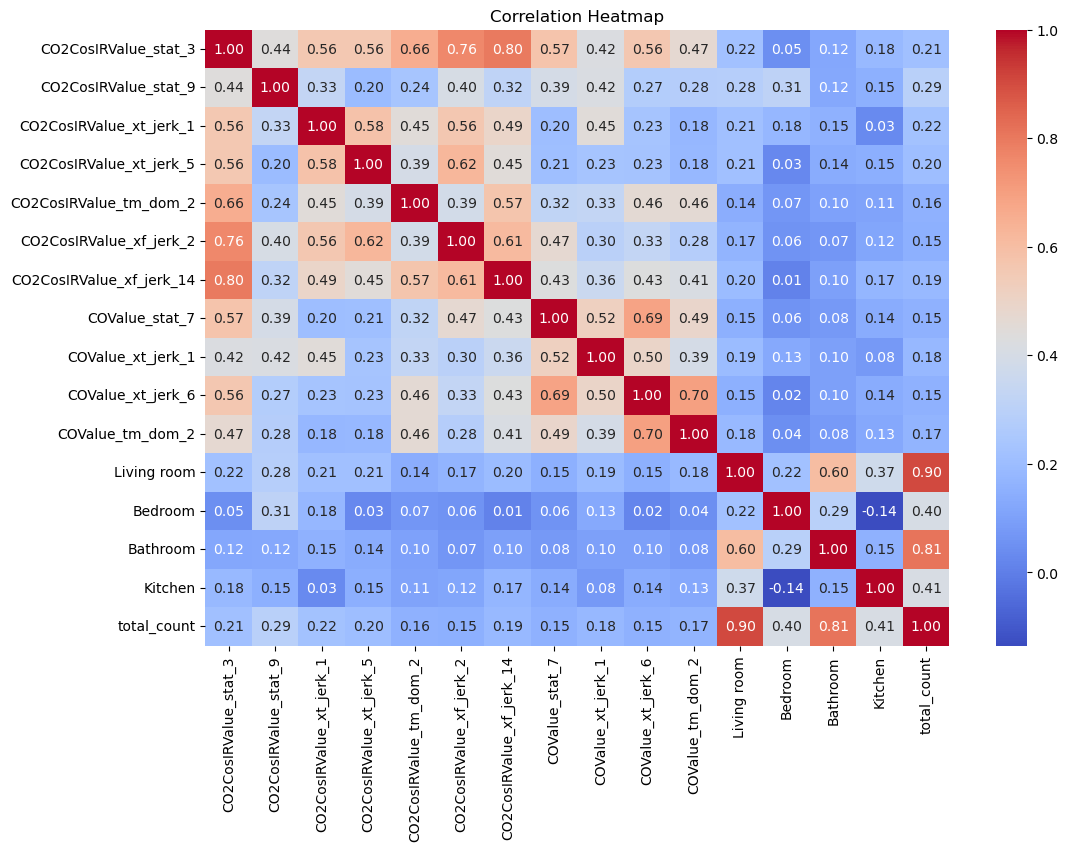

In [339]:
import seaborn as sns
correlation_matrix = test_df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [122]:
#test_df = final_features_df.dropna()
X = test_df.drop(drop_features, axis=1)
X = X.values
y = test_df[target_feature]

In [130]:
from sklearn.ensemble import RandomForestRegressor
regr = RandomForestRegressor(max_depth=5, random_state=0, n_estimators=45)
regr.fit(X, y)

RandomForestRegressor(max_depth=5, n_estimators=45, random_state=0)

In [131]:
y_pred = regr.predict(X)

In [132]:
regr.score(X, y)

0.3084862100175162

In [126]:
from sklearn.metrics import mean_squared_error
mean_squared_error(y, y_pred)

41.4097987738655

In [127]:
import matplotlib.pyplot as plt

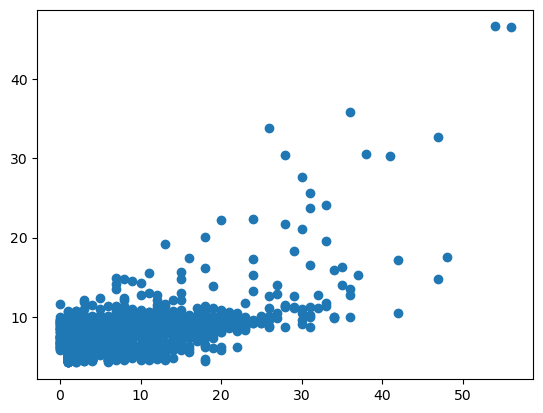

In [128]:
plt.scatter(y, y_pred)